# Case 1, chapter 6: The bill for the near-tie: which model, at what cost?

*Applies chapter 1 (the model justification: claim, evidence, caveat, action) and chapter 2 (the error bill in rupees under the chosen threshold) to the bank's 41,188 calls.*

**Who needs the answer.** Meera's steering committee on Monday, and Anand in Finance, who signs the campaign budget. A wrong pick costs Kalpa buyers it could have reached with the same 1,000 calls.

**The questions on the way.** Which of Thursday's three models has the smallest bill at the cost threshold? Does the model matter at all at Rs 40 against Rs 1,200? Under a budget of 1,000 calls, how many more buyers does the highest-AUC model find, and is that gap bigger than luck?

**What you will be able to do.** Compute the error bill for three models at two operating points, size the gap between them in rupees, test whether the gap is real, and write the memo's claim and evidence from your own numbers.

**Search terms.** expected cost of a classifier, precision at k, bootstrap confidence interval, model selection.

## What does Thursday hand us?

The week's pipeline, reloaded in code: the bank's file, Wednesday's honest columns (no `duration`, `pdays` split into a flag and the days), the test slice sealed in its envelope since Monday. The first run downloads about 1 MB; later runs read the cached copy.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 3.6), "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10.5, "axes.titleweight": "bold"})
INK, VIOLET, ROSE, GREEN, MUTED, LILAC = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690", "#CFC9EE"

def check(label, ok):
    """Print PASS or FAIL on its own line; a failed check never stops the notebook."""
    print(("PASS  " if ok else "FAIL  ") + label)

# The Week 5 pipeline: the same file, columns and split every case notebook starts from.
import io, zipfile, pathlib, urllib.request
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)

def load_bank():
    """UCI Bank Marketing, bank-additional-full.csv (CC BY 4.0), cached after the first download."""
    f = CACHE / "bank-additional-full.csv"
    if not f.exists():
        url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
        outer = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=60).read()))
        inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
        f.write_bytes(inner.read("bank-additional/bank-additional-full.csv"))
    return pd.read_csv(f, sep=";")

PROFILE = ["age", "job", "marital", "education", "default", "housing", "loan"]
HISTORY = ["contact", "month", "day_of_week", "campaign", "previous", "poutcome"]
ECONOMY = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

bank = load_bank()
# Wednesday's honest set: no duration, and pdays split into a flag and the days for those contacted.
bank["never_contacted"] = (bank["pdays"] == 999).astype(int)
bank["days_since"] = bank["pdays"].where(bank["pdays"] != 999, 0)
COLS = PROFILE + HISTORY + ECONOMY + ["never_contacted", "days_since"]
X, y = bank[COLS], (bank["y"] == "yes").astype(int)

# The test slice is sealed first (the envelope on the wall); the rest splits 75/25.
rest, test = train_test_split(bank.index, test_size=0.20, stratify=y, random_state=42)
train, val = train_test_split(rest, test_size=0.25, stratify=y.loc[rest], random_state=42)
NUM = [c for c in COLS if pd.api.types.is_numeric_dtype(bank[c])]
CAT = [c for c in COLS if c not in NUM]

def logistic():
    prep = ColumnTransformer([("num", StandardScaler(), NUM),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=3000))])

print(f"{len(bank):,} rows; train {len(train):,}, validation {len(val):,}, test {len(test):,} (sealed)")
print(f"buyers in validation: {y[val].sum():,} of {len(val):,} ({y[val].mean():.1%})")

41,188 rows; train 24,712, validation 8,238, test 8,238 (sealed)
buyers in validation: 928 of 8,238 (11.3%)


In [2]:
check("41,188 rows, as the dataset page states", len(bank) == 41188)
check("train, validation and test add to every row", len(train) + len(val) + len(test) == len(bank))
check("no duration column among the model's inputs", "duration" not in COLS)

PASS  41,188 rows, as the dataset page states
PASS  train, validation and test add to every row
PASS  no duration column among the model's inputs


## The options: which of three models goes in the memo?

Thursday left three models within a few hundredths of AUC of each other: a regularised logistic model, a depth-limited tree tuned by cross-validation on the training rows, and gradient boosting. All three are fitted on the same 24,712 training rows and compared on the same 8,238 validation rows.

**Predict before you run.** At the cost threshold of 0.032, which model has the smallest error bill? a) boosting, since its AUC is highest; b) the tree; c) logistic; d) all three within one percent of each other.

In [3]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

ordinal = ColumnTransformer([("num", "passthrough", NUM),
                             ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT)])
tree = GridSearchCV(Pipeline([("prep", ordinal), ("model", DecisionTreeClassifier(random_state=42))]),
                    {"model__max_depth": [5, 6, 7, 8], "model__min_samples_leaf": [20, 50, 100]},
                    scoring="roc_auc", cv=StratifiedKFold(5, shuffle=True, random_state=42))
boost = Pipeline([("prep", ordinal), ("model", HistGradientBoostingClassifier(random_state=42))])

models = {"logistic": logistic(), "tuned tree": tree, "boosting": boost}
P = {}
for name, m in models.items():
    m.fit(X.loc[train], y[train])
    P[name] = m.predict_proba(X.loc[val])[:, 1]
yv = y[val].values
print("tree picked by cross-validation:", tree.best_params_)
pd.DataFrame({name: {"validation AUC": round(roc_auc_score(yv, p), 3), "mean score": round(p.mean(), 3)}
              for name, p in P.items()}).T

tree picked by cross-validation: {'model__max_depth': 7, 'model__min_samples_leaf': 20}


,validation AUC,mean score
logistic,0.795,0.114
tuned tree,0.787,0.114
boosting,0.803,0.113


## What does each model cost at the cost threshold?

The bill counts only the two mistakes, in Tuesday's rupees: every wasted call costs Rs 40, every buyer never called costs Rs 1,200 of margin. A buyer who is called is the gain the bill is set against, so it never enters the bill. The threshold that makes the bill smallest, when the scores are honest probabilities, is `40 / (40 + 1,200) = 0.032`.

In [4]:
CALL, MISS = 40, 1200          # Rs per wasted nudge, Rs of margin per missed buyer (Tuesday)
COST_T = CALL / (CALL + MISS)   # act when P(buy) is above 40 / 1,240 = 0.032

def bill_at(y_true, p, t):
    """The error bill at threshold t: wasted calls x Rs 40 plus missed buyers x Rs 1,200."""
    y_true, called = np.asarray(y_true), np.asarray(p) >= t
    tp = int((called & (y_true == 1)).sum()); fp = int((called & (y_true == 0)).sum())
    fn = int((~called & (y_true == 1)).sum())
    return {"called": tp + fp, "found": tp, "wasted": fp, "missed": fn, "bill_rs": CALL * fp + MISS * fn}

def bill_top(y_true, p, k):
    """The bill when the budget allows k calls: call the k highest scores."""
    y_true = np.asarray(y_true); top = np.argsort(-np.asarray(p), kind="stable")[:k]
    tp = int(y_true[top].sum()); fp, fn = k - tp, int(y_true.sum()) - tp
    return {"called": k, "found": tp, "wasted": fp, "missed": fn, "bill_rs": CALL * fp + MISS * fn,
            "score_at_cut": round(float(np.asarray(p)[top[-1]]), 3)}

rows = {name: bill_at(yv, p, COST_T) for name, p in P.items()}
rows["call everyone"] = bill_at(yv, np.ones(len(yv)), 0.5)
rows["call nobody"] = bill_at(yv, np.zeros(len(yv)), 0.5)
rows["logistic at 0.5"] = bill_at(yv, P["logistic"], 0.5)
table = pd.DataFrame(rows).T
table

,called,found,wasted,missed,bill_rs
logistic,7412,910,6502,18,281680
tuned tree,6976,895,6081,33,282840
boosting,7512,912,6600,16,283200
call everyone,8238,928,7310,0,292400
call nobody,0,0,0,928,1113600
logistic at 0.5,331,214,117,714,861480


**What happened.** The answer is d. The three bills sit within Rs 1,520 of each other on a bill near Rs 2.8 lakh, and boosting, the highest AUC, has the largest of the three. The trap is the sentence "boosting has the best AUC, so it saves the most money": at this cost ratio every model calls about nine people in ten, and the logistic bill is only about 4 percent below calling all 8,238 customers. At 0.5, the default, the bill looks small on the call count and is the largest of all, because nearly every buyer is missed.

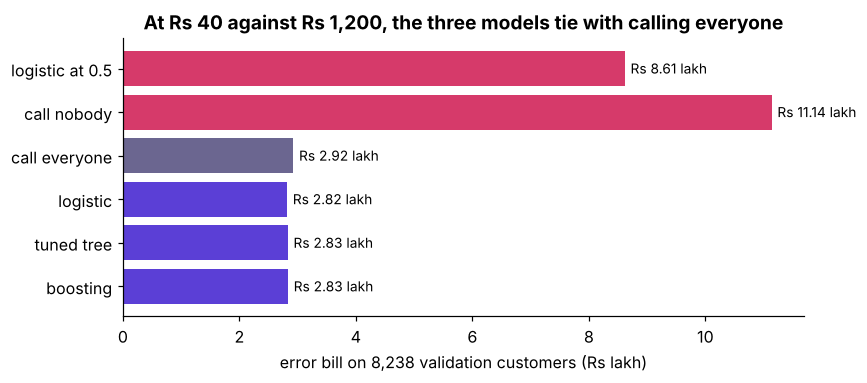

In [5]:
fig, ax = plt.subplots()
names = ["logistic at 0.5", "call nobody", "call everyone", "logistic", "tuned tree", "boosting"]
vals = [table.loc[n, "bill_rs"] / 1e5 for n in names]
colors = [ROSE, ROSE, MUTED, VIOLET, VIOLET, VIOLET]
ax.barh(names, vals, color=colors)
for i, v in enumerate(vals):
    ax.text(v + 0.1, i, f"Rs {v:.2f} lakh", va="center", fontsize=9)
ax.set_xlabel("error bill on 8,238 validation customers (Rs lakh)")
ax.set_title("At Rs 40 against Rs 1,200, the three models tie with calling everyone")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

## Where does the model earn its keep?

Marketing can afford 1,000 calls for these 8,238 customers. The cost threshold would call about 7,400, so the budget binds, and the decision becomes a ranking: call the 1,000 highest scores. Calling 1,000 people at random would find about 113 buyers, the 11.3 percent base rate.

In [6]:
K = 1000
top = pd.DataFrame({name: bill_top(yv, p, K) for name, p in P.items()}).T
top = top.astype({c: int for c in ["called", "found", "wasted", "missed", "bill_rs"]})
top["precision"] = (top["found"] / K).round(3)
top

,called,found,wasted,missed,bill_rs,score_at_cut,precision
logistic,1000,462,538,466,580720,0.245,0.462
tuned tree,1000,469,531,459,572040,0.290,0.469
boosting,1000,475,525,453,564600,0.282,0.475


## Is 13 more buyers a real gap, or luck in which customers landed in validation?

Boosting finds 13 more buyers than logistic in the same 1,000 calls. Each extra buyer turns a wasted call into a sale, so it is worth `Rs 40 + Rs 1,200 = Rs 1,240` on the bill. To see whether 13 is more than the luck of the draw, resample the 8,238 validation customers with replacement 300 times and recount the gap each time: a paired bootstrap, the Week 1 permutation idea run on a model comparison.

boosting minus logistic, buyers per 1,000 calls: mean 13.8, 95 percent band -1 to 28
in rupees: Rs 17,071 per 1,000 calls, band Rs -1,240 to Rs 34,720


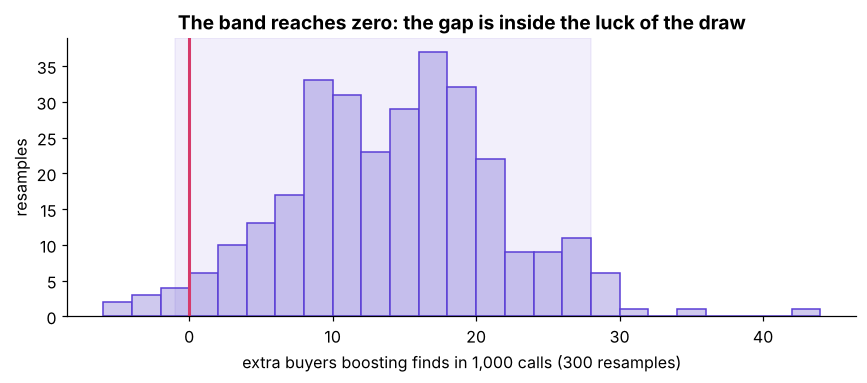

In [7]:
rng = np.random.default_rng(0)
def found_top(yt, p, k):
    return yt[np.argsort(-p, kind="stable")[:k]].sum()
gaps = []
for _ in range(300):
    s = rng.integers(0, len(yv), len(yv))
    gaps.append(found_top(yv[s], P["boosting"][s], K) - found_top(yv[s], P["logistic"][s], K))
gaps = np.array(gaps)
lo, hi = np.percentile(gaps, [2.5, 97.5])
print(f"boosting minus logistic, buyers per 1,000 calls: mean {gaps.mean():.1f}, 95 percent band {lo:.0f} to {hi:.0f}")
print(f"in rupees: Rs {gaps.mean() * 1240:,.0f} per 1,000 calls, band Rs {lo * 1240:,.0f} to Rs {hi * 1240:,.0f}")

fig, ax = plt.subplots()
ax.hist(gaps, bins=25, color=LILAC, edgecolor=VIOLET)
ax.axvline(0, color=ROSE, lw=2); ax.axvspan(lo, hi, color=VIOLET, alpha=0.08)
ax.set_xlabel("extra buyers boosting finds in 1,000 calls (300 resamples)")
ax.set_ylabel("resamples"); ax.set_title("The band reaches zero: the gap is inside the luck of the draw")
plt.tight_layout(); plt.show()

## A second route to the same rupees

The bill under a fixed budget moves only through buyers found: each one found is a call that stops being wasted and a buyer who stops being missed. So the bill gap between two models must equal the gap in buyers times Rs 1,240.

In [8]:
gap_buyers = int(top.loc["boosting", "found"] - top.loc["logistic", "found"])
gap_rupees = int(top.loc["logistic", "bill_rs"] - top.loc["boosting", "bill_rs"])
print(f"gap in buyers {gap_buyers}, x Rs 1,240 = Rs {gap_buyers * 1240:,}; gap in the two bills = Rs {gap_rupees:,}")
check("the bill gap equals the buyer gap times Rs 1,240", gap_rupees == gap_buyers * 1240)
check("every bill reconciles: wasted plus found equals called", all(r["wasted"] + r["found"] == r["called"] for r in rows.values()))
check("at 0.032 the three bills sit within 1 percent of each other",
      (table.loc[["logistic", "tuned tree", "boosting"], "bill_rs"].max() / table.loc[["logistic", "tuned tree", "boosting"], "bill_rs"].min()) < 1.01)
check("the 95 percent band of the gap reaches zero, so the gap is a tie on this slice", lo <= 0)

gap in buyers 13, x Rs 1,240 = Rs 16,120; gap in the two bills = Rs 16,120
PASS  the bill gap equals the buyer gap times Rs 1,240
PASS  every bill reconciles: wasted plus found equals called
PASS  at 0.032 the three bills sit within 1 percent of each other
PASS  the 95 percent band of the gap reaches zero, so the gap is a tie on this slice


## What do the claim and the evidence say, in the committee's words?

The simpler model is recommended when it ties, and the memo says why out loud: the gap is inside the band, and logistic is the model the team can explain, rerun and check each week. The flip condition goes in the memo too: boosting ships if a fresh month shows its lead clear of zero.

In [9]:
lg, bo = top.loc["logistic"], top.loc["boosting"]
print("CLAIM.    Call the 1,000 customers the logistic model scores highest each campaign "
      f"(score above {lg['score_at_cut']:.3f}).")
print(f"EVIDENCE. On 8,238 validation customers it finds {int(lg['found'])} buyers in 1,000 calls against about "
      f"{yv.mean() * 1000:.0f} at random; boosting finds {int(bo['found'])}, a gap of {gap_buyers} "
      f"(Rs {gap_buyers * 1240:,}) whose 95 percent band runs from {lo:.0f} to {hi:.0f}, so it is a tie.")
print(f"          Without the budget, at the cost threshold, every model's bill is within 4 percent of calling everyone.")

CLAIM.    Call the 1,000 customers the logistic model scores highest each campaign (score above 0.245).
EVIDENCE. On 8,238 validation customers it finds 462 buyers in 1,000 calls against about 113 at random; boosting finds 475, a gap of 13 (Rs 16,120) whose 95 percent band runs from -1 to 28, so it is a tie.
          Without the budget, at the cost threshold, every model's bill is within 4 percent of calling everyone.


## What did this chapter establish, and what does the next one add?

| Question | Answer from this run |
|---|---|
| Smallest bill at 0.032? | All three within about 0.5 percent; boosting's is the largest of the three |
| Does the model matter at Rs 40 against Rs 1,200? | Barely: the bill is about 4 percent below calling everyone |
| Where does it matter? | Under the 1,000-call budget: about 460 to 475 buyers against 113 at random |
| Is boosting's lead real? | 13 buyers, band reaching zero: a tie, so the simpler model is recommended |

The next notebook asks what this bill will look like next year, by training on the early months and scoring the late ones.